# Notebook 02 — Image Preprocessing and Dataset Splitting

## Objectives

In this notebook, we will:

1. Inspect unusual image channel representations.
2. Identify corrupted or unsupported images.
3. Check for duplicate images before splitting.
4. Split the dataset into training, validation, and test sets.
5. Resize images to a consistent input size.
6. Normalize pixel values.
7. Prepare the data for CNN training.

The original images will remain unchanged. All preprocessing
will be performed in Python.


In [8]:
from pathlib import Path

import cv2
import numpy as np
import matplotlib.pyplot as plt

data_dir = Path("../data/raw")

classes = sorted([
    folder.name
    for folder in data_dir.iterdir()
    if folder.is_dir()
])

extensions = {".jpg", ".jpeg", ".png", ".bmp"}

print("Classes:", classes)


Classes: ['glioma', 'meningioma', 'notumor', 'pituitary']


In [9]:
color_images = []
other_images = []
bad_files = []

for label in classes:

    for path in (data_dir / label).rglob("*"):

        if not path.is_file():
            continue

        if path.suffix.lower() not in extensions:
            continue

        image = cv2.imread(
            str(path),
            cv2.IMREAD_UNCHANGED
        )

        if image is None:
            bad_files.append(path)
            continue

        if image.ndim == 3 and image.shape[2] == 3:

            if not (
                np.array_equal(image[:, :, 0], image[:, :, 1])
                and np.array_equal(image[:, :, 1], image[:, :, 2])
            ):
                color_images.append((path, label))

        elif image.ndim != 2:
            other_images.append((path, label, image.shape))

print("Images with different channels:", len(color_images))
print("Images with unusual shapes:", len(other_images))
print("Unreadable images:", len(bad_files))

for path, label, shape in other_images:
    print(label, path.name, shape)


Images with different channels: 127
Images with unusual shapes: 3
Unreadable images: 0
notumor Tr-no_1011.jpg (664, 550, 4)
notumor Tr-no_1019.jpg (400, 393, 4)
notumor Tr-no_1020.jpg (454, 442, 4)


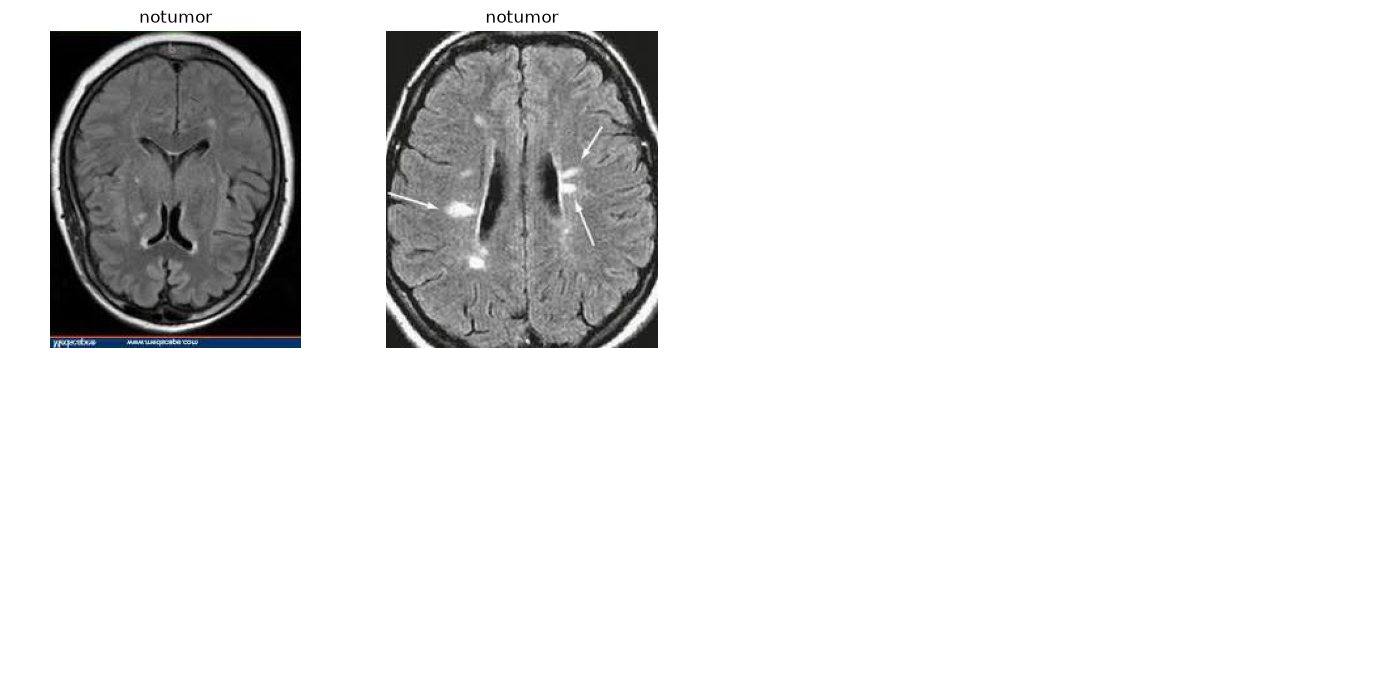

In [10]:
samples = []

for label in classes:
    class_images = [
        item for item in color_images
        if item[1] == label
    ]

    samples.extend(class_images[:2])

fig, axes = plt.subplots(2, 4, figsize=(14, 7))

for ax in axes.flat:
    ax.axis("off")

for ax, (path, label) in zip(axes.flat, samples):

    image = cv2.imread(str(path), cv2.IMREAD_COLOR)
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    ax.imshow(image)
    ax.set_title(label)
    ax.axis("off")

plt.tight_layout()
plt.show()


## Exact Duplicate Check

Duplicate images can cause data leakage if copies of the same image
appear in different dataset splits.

We will compare file hashes to identify files with identical
contents before splitting the dataset.

This detects exact file duplicates. It does not detect every
visually identical image saved with different compression or
metadata.



## 1. Understanding Image Channels

The dataset contains 7,023 readable images with different
channel representations.

| Representation | Number of images |
|---|---:|
| Three identical channels | 3,800 |
| Single-channel images | 3,093 |
| Three different channels | 127 |
| Other channel arrangements | 3 |
| Total | 7,023 |

### Three identical channels

These images have three channels, but the values are identical
across all three channels. Their pixel content is grayscale.

### Single-channel images

These images store one intensity value per pixel. Their
shape is (height, width), without an explicit channel dimension.

### Three different channels

At least some pixels have different values across their channels.
This may represent genuine color information, annotations,
or other image artifacts.

### Four-channel images

Three images have four channels. We must inspect their file
encoding before assuming that the fourth channel represents
transparency.

### Preprocessing implication

The CNN requires a consistent input representation. We will
inspect unusual images and investigate possible artifacts before
choosing grayscale or three-channel input for the complete dataset.


In [11]:

from PIL import Image

for path, label, shape in other_images:

    with Image.open(path) as image:

        print("Class:", label)
        print("File:", path.name)
        print("Pillow mode:", image.mode)
        print("Image size:", image.size)
        print("OpenCV shape:", shape)
        print()


Class: notumor
File: Tr-no_1011.jpg
Pillow mode: RGBA
Image size: (550, 664)
OpenCV shape: (664, 550, 4)

Class: notumor
File: Tr-no_1019.jpg
Pillow mode: RGBA
Image size: (393, 400)
OpenCV shape: (400, 393, 4)

Class: notumor
File: Tr-no_1020.jpg
Pillow mode: RGBA
Image size: (442, 454)
OpenCV shape: (454, 442, 4)



In [12]:
from collections import Counter

channel_counts = {
    label: Counter()
    for label in classes
}

for label in classes:

    for path in (data_dir / label).rglob("*"):

        if not path.is_file():
            continue

        if path.suffix.lower() not in extensions:
            continue

        image = cv2.imread(
            str(path),
            cv2.IMREAD_UNCHANGED
        )

        if image is None:
            continue

        if image.ndim == 2:
            kind = "single-channel"

        elif image.shape[2] == 3:

            same = (
                np.array_equal(image[:, :, 0], image[:, :, 1])
                and np.array_equal(image[:, :, 1], image[:, :, 2])
            )

            kind = (
                "three identical channels"
                if same
                else "three different channels"
            )

        else:
            kind = "other channel arrangement"

        channel_counts[label][kind] += 1

for label in classes:

    print("\n", label)

    for kind, count in channel_counts[label].items():
        print(kind, ":", count)



 glioma
three identical channels : 195
single-channel : 1426

 meningioma
three identical channels : 937
single-channel : 708

 notumor
three identical channels : 1841
three different channels : 127
single-channel : 29
other channel arrangement : 3

 pituitary
three identical channels : 827
single-channel : 930


In [13]:
from PIL import Image

for path, label, shape in other_images:

    with Image.open(path) as image:

        rgba = np.array(image.convert("RGBA"))
        alpha = rgba[:, :, 3]

        print("File:", path.name)
        print("Actual format:", image.format)
        print("Pillow mode:", image.mode)
        print("Size:", image.size)
        print("Alpha minimum:", alpha.min())
        print("Alpha maximum:", alpha.max())
        print("Transparent pixels:", np.sum(alpha == 0))
        print("Partially transparent pixels:",
              np.sum((alpha > 0) & (alpha < 255)))
        print()


File: Tr-no_1011.jpg
Actual format: PNG
Pillow mode: RGBA
Size: (550, 664)
Alpha minimum: 255
Alpha maximum: 255
Transparent pixels: 0
Partially transparent pixels: 0

File: Tr-no_1019.jpg
Actual format: PNG
Pillow mode: RGBA
Size: (393, 400)
Alpha minimum: 255
Alpha maximum: 255
Transparent pixels: 0
Partially transparent pixels: 0

File: Tr-no_1020.jpg
Actual format: PNG
Pillow mode: RGBA
Size: (442, 454)
Alpha minimum: 255
Alpha maximum: 255
Transparent pixels: 0
Partially transparent pixels: 0



In [ ]:

import hashlib
from collections import defaultdict

hash_groups = defaultdict(list)

for label in classes:

    folder = data_dir / label

    for path in folder.rglob("*"):

        if not path.is_file():
            continue

        if path.suffix.lower() not in extensions:
            continue

        image_hash = hashlib.sha256(
            path.read_bytes()
        ).hexdigest()

        hash_groups[image_hash].append((path, label))


duplicate_groups = [
    group
    for group in hash_groups.values()
    if len(group) > 1
]

cross_class_duplicates = [
    group
    for group in duplicate_groups
    if len({label for path, label in group}) > 1
]

duplicate_file_count = sum(
    len(group) for group in duplicate_groups
)

print("Total image files:", sum(
    len(group) for group in hash_groups.values()
))

print("Unique file contents:", len(hash_groups))
print("Exact duplicate groups:", len(duplicate_groups))
print("Files in duplicate groups:", duplicate_file_count)
print(
    "Duplicate groups across different classes:",
    len(cross_class_duplicates)
)

for group in cross_class_duplicates[:10]:

    print("\nCross-class duplicate:")

    for path, label in group:
        print(label, path)


NameError: name 'records' is not defined


## 2. Channel Distribution and Potential Dataset Bias

The channel audit revealed that image representation differs
substantially between classes.

All 127 images with three different channel values belong to
the notumor class. The three four-channel images also belong
to that class.

This may indicate differences in the sources, formats, or
annotations of images across classes.

A CNN could potentially learn these differences as shortcuts
instead of learning relevant anatomical features.

### Planned investigation

1. Inspect the actual formats of four-channel images.
2. Check for exact duplicate files.
3. Investigate class-specific annotations and visual artifacts.
4. Choose a consistent image representation.
5. Split the dataset before fitting any data-dependent
   preprocessing operations.

We will not delete images solely because their channel
representation differs. Any exclusions must be justified
by a documented data-quality reason.



## 3. Investigating Four-Channel Images

Three files have a `.jpg` extension but are encoded as PNG.

Pillow identifies their mode as RGBA. Their alpha values are
255 for every pixel, meaning the images are fully opaque.

Therefore, the alpha channel contains no transparency information
for these files.

During preprocessing, we can discard the redundant alpha channel
while preserving the visible image content. We will standardize
the image representation later in the preprocessing pipeline.
